# 09 — Unified model comparison (Phase 3 · Step 5)

This notebook puts every model of the project side by side — **without refitting anything**. Every number is **recomputed from the saved forecast files** written by the model notebooks
(04 classical models, 05 intermittent models, 06 XGBoost, 07 LSTM/GRU, 08 Prophet), after checking that those files are valid, that they cover exactly the same days, and that no model name hides two different forecasts.

Two rules shape the whole notebook:

1. **Two separate comparisons.** The **aggregate series** (the daily total of 823 products, thousands of units per day) and the **item-level series** (one product, a few units per day) are on completely different scales. They are compared in separate sections, with separate tables and plots, and
   **an aggregate error is never ranked against an item-level error**.
2. **Descriptions, not verdicts.** With five consecutive folds, one store and one department, no significance test can be justified. The notebook reports the mean, spread and range across folds and says where measures disagree; it does not declare a universal winner.

The final holdout (2016-04-25 → 2016-05-22) is **not read, scored or shown** anywhere in this notebook.

## 1. Objective

*Given everything that was run in Phases 2 and 3 under one identical protocol (five expanding walk-forward folds, 28-day horizon), how do the models compare — on the aggregate series and, separately, on the 20 selected items — across several error measures, and how much do the results vary from fold to fold?*

## 2. Method

**Protocol (identical for every model).** Five expanding folds, each forecasting 28 days: 2015-12-07→2016-01-03, 2016-01-04→2016-01-31, 2016-02-01→2016-02-28, 2016-02-29→2016-03-27 and 2016-03-28→2016-04-24. The model is fitted on all days before the fold's first forecast day and nothing else.

**Measures** (all recomputed here from the saved forecasts; *u* = actual, *f* = forecast):

| Measure | Definition | Notes |
|---|---|---|
| MAE | mean \|u − f\| | in units per day; lower is better |
| RMSE | √ mean (u − f)² | punishes large misses more than MAE |
| MAPE | mean \|u − f\| / u, in % | **zero-protected**: days with u = 0 are excluded and *counted*; undefined on a fold with no positive actual |
| WAPE | Σ\|u − f\| / Σu | a scale-free "total error share"; undefined if nothing was sold |
| bias | mean (f − u) | positive = over-forecast |
| MASE | MAE ÷ the MAE of a seasonal-naive (lag-7) forecast **on that fold's training window** | below 1 beats that benchmark; undefined when the training scale is zero |

For each model the notebook shows each fold's value, then the **mean, standard deviation (sample, across the five folds), minimum and maximum**. The standard deviation describes how much the result moves between windows; it is not a confidence interval.

**Identifier and grid checks.** Before anything is scored, every saved table is audited (no date after 2016-04-24, every fold present with exactly 28 consecutive days, actuals equal the development series, finite non-negative forecasts). Tables are then combined only if they score exactly the same (fold, date[, item]) cells with identical actual values, and a model name that occurs in two files must carry identical forecasts in both (a re-run), otherwise the notebook stops.

**Missing artifacts.** If a file is missing or fails its audit, the audit table says so with the exact command that creates it. That model is then simply absent from the comparison — it is never replaced by a stand-in forecast.

**Variants.** Pre-declared *primary* variants are `LSTM(calendar)`, `GRU(calendar)`, `Prophet(additive)` and `XGBoost(pooled)`; the other variants are *ablations* (they answer "does the calendar information help?") and are drawn with lighter bars.

## 3. Setup and reproducibility

Run from the project root with `python -m jupyter nbconvert --to notebook --execute --inplace notebooks/09_model_comparison.ipynb` (a few seconds once the model notebooks have been run).

In [1]:
import sys
from pathlib import Path


def _find_project_root(start: Path) -> Path:
    """Walk up from `start` until a directory containing config.yaml is found."""
    for candidate in [start, *start.parents]:
        if (candidate / "config.yaml").exists():
            return candidate
    raise FileNotFoundError(
        f"Could not find config.yaml in any parent directory of '{start}'. Run this notebook from within the project."
    )


PROJECT_ROOT = _find_project_root(Path.cwd())
sys.path.insert(0, str(PROJECT_ROOT))

import logging
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data.aggregate_series import load_aggregate_development
from src.evaluation import model_comparison as mc
from src.evaluation.forecast_artifacts import load_selected_item_series
from src.evaluation.intermittent_experiment import plot_class_metric
from src.utils.config import load_config
from src.utils.provenance import build_run_metadata, file_sha256, write_json

warnings.filterwarnings("ignore")
logging.getLogger().setLevel(logging.WARNING)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10, "axes.grid": True, "grid.alpha": 0.3})

config = load_config()
p2, p3 = config["phase2"], config["phase3"]
HORIZON, N_FOLDS = int(config["backtest"]["horizon"]), int(config["backtest"]["n_folds"])
metrics_dir = PROJECT_ROOT / p3["metrics_dir"]
reports_dir = PROJECT_ROOT / config["reports"]["phase3_dir"]
for directory in (metrics_dir, reports_dir):
    directory.mkdir(parents=True, exist_ok=True)


def save_figure(fig, filename):
    fig.savefig(reports_dir / filename, dpi=150, bbox_inches="tight")


def save_table(table, key):
    table.to_csv(metrics_dir / p3[key], index=False, lineterminator="\n")


dev_series, window = load_aggregate_development(config)
item_series = load_selected_item_series(config)
item_index = next(iter(item_series.values())).index
print(f"Aggregate development series: {len(dev_series)} days, {dev_series.index[0].date()} -> {dev_series.index[-1].date()}")
print(f"Item-level development series: {len(item_series)} items x {len(item_index)} days")
print(f"Reserved final holdout: {window.holdout_start.date()} -> {window.holdout_end.date()} (dates only; never loaded here)")

Aggregate development series: 1913 days, 2011-01-29 -> 2016-04-24
Item-level development series: 20 items x 1913 days
Reserved final holdout: 2016-04-25 -> 2016-05-22 (dates only; never loaded here)


## 4. Which artifacts exist, and are they valid?

In [2]:
agg_sources, item_sources_ = mc.aggregate_sources(config), mc.item_sources(config)
agg_tables, agg_audit = mc.load_sources(agg_sources, dev_series=dev_series, config=config, horizon=HORIZON, n_folds=N_FOLDS)
item_tables, item_audit = mc.load_sources(item_sources_, item_series=item_series, dev_dates=item_index, config=config, horizon=HORIZON, n_folds=N_FOLDS)
audit = pd.concat([agg_audit, item_audit], ignore_index=True)
save_table(audit, "comparison_audit_filename")

display(audit[["artifact", "scope", "status", "rows", "models"]].set_index("artifact"))
problems = audit[audit["status"] != "ok"]
if problems.empty:
    print("All saved artifacts exist and pass their audit.")
else:
    print(f"{len(problems)} artifact(s) unavailable. Models from these files are ABSENT from the comparison below (nothing is substituted):")
    for row in problems.itertuples():
        print(f"  - {row.artifact} [{row.status}]: {row.detail}")

,scope,status,rows,models
artifact,,,,
seasonal_naive_backtest_forecasts.csv,aggregate,ok,140,SeasonalNaive
arima_backtest_forecasts.csv,aggregate,ok,140,"ARIMA(6, 1, 1)"
sarima_backtest_forecasts.csv,aggregate,ok,140,"SARIMA(6, 1, 1)x(0, 0, 2, 7)"
holt_winters_backtest_forecasts.csv,aggregate,ok,140,HoltWinters(trend=add)
lstm_gru_backtest_forecasts.csv,aggregate,ok,560,"GRU(calendar), GRU(univariate), LSTM(calendar)..."
prophet_backtest_forecasts.csv,aggregate,ok,420,"Prophet(additive), Prophet(additive,no-regress..."
item_level_backtest_long.csv,item,ok,8400,"Croston(alpha=0.1), SeasonalNaive, TSB(alpha=0..."
xgboost_item_level_backtest_long.csv,item,ok,11200,"XGBoost(per-item), XGBoost(pooled), XGBoost(po..."
intermittent_item_level_backtest_long.csv,item,ok,8400,"Croston(alpha=0.1), SeasonalNaive, TSB(alpha=0..."


All saved artifacts exist and pass their audit.


## 5. Results: aggregate series, all models on the daily total

*Scale: thousands of units per day. Everything in this section is on the aggregate series only.*

In [3]:
if len(agg_tables) < 2:
    raise FileNotFoundError("Fewer than two aggregate artifacts are available; nothing to compare. See the audit table above for the commands that create them.")

agg_table, agg_notes = mc.combine_tables(agg_tables, "aggregate")
for note in agg_notes:
    print("note:", note)
agg_models = list(dict.fromkeys(agg_table["model"]))
print(f"{len(agg_models)} models on one identical grid ({agg_table['fold'].nunique()} folds x {HORIZON} days, same actual values):")
for model in agg_models:
    print(f"  {mc.model_family(model):22s} {model}{'   [primary]' if model in mc.PRIMARY_MODELS else ''}")

agg_folds = mc.aggregate_fold_metrics(agg_table, dev_series, HORIZON, N_FOLDS)
agg_summary = mc.model_summary(agg_folds)
save_table(agg_folds.drop(columns=["primary"]), "comparison_aggregate_fold_filename")
save_table(agg_summary, "comparison_aggregate_summary_filename")
print(f"\nFailed folds in the saved tables: {int((~agg_folds['success']).sum())} of {len(agg_folds)}")

11 models on one identical grid (5 folds x 28 days, same actual values):
  classical (Phase 2)    SeasonalNaive
  classical (Phase 2)    ARIMA(6, 1, 1)
  classical (Phase 2)    SARIMA(6, 1, 1)x(0, 0, 2, 7)
  classical (Phase 2)    HoltWinters(trend=add)
  neural (Phase 3)       GRU(calendar)   [primary]
  neural (Phase 3)       GRU(univariate)
  neural (Phase 3)       LSTM(calendar)   [primary]
  neural (Phase 3)       LSTM(univariate)
  Prophet (Phase 3)      Prophet(additive)   [primary]
  Prophet (Phase 3)      Prophet(additive,no-regressors)
  Prophet (Phase 3)      Prophet(multiplicative)

Failed folds in the saved tables: 0 of 55


### 5.1 Fold by fold

Each cell is one model on one 28-day window (units per day). Reading across a row shows how stable a model is; reading down a column shows how the models compare on the *same* days.

In [4]:
for metric in ("MAE", "RMSE"):
    wide = agg_folds.pivot(index="model", columns="fold", values=metric).reindex(agg_models)
    wide.columns = [f"fold {c}" for c in wide.columns]
    wide["mean"] = wide.mean(axis=1)
    wide["std (folds)"] = wide[[c for c in wide.columns if c.startswith("fold")]].std(axis=1, ddof=1)
    print(f"{metric} by fold (units/day, aggregate series)")
    display(wide.round(1))

MAE by fold (units/day, aggregate series)


,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std (folds)
model,,,,,,,
SeasonalNaive,253.4,323.9,289.1,189.6,226.7,256.6,52.4
"ARIMA(6, 1, 1)",217.3,323.1,244.8,219.8,223.1,245.6,44.7
"SARIMA(6, 1, 1)x(0, 0, 2, 7)",269.8,314.9,237.1,164.7,153.3,228.0,68.8
HoltWinters(trend=add),270.1,249.6,167.3,143.5,136.2,193.3,62.2
GRU(calendar),224.1,289.9,185.6,167.4,129.6,199.3,61.0
GRU(univariate),278.7,285.1,174.7,148.7,128.5,203.1,73.8
LSTM(calendar),231.2,217.6,168.9,165.4,125.0,181.6,42.9
LSTM(univariate),277.1,314.9,166.0,160.3,130.1,209.7,81.0
Prophet(additive),271.8,170.4,255.8,231.5,181.6,222.2,44.7


RMSE by fold (units/day, aggregate series)


,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std (folds)
model,,,,,,,
SeasonalNaive,409.0,391.0,333.6,241.6,270.0,329.0,73.1
"ARIMA(6, 1, 1)",388.1,414.8,292.9,301.0,270.1,333.4,63.9
"SARIMA(6, 1, 1)x(0, 0, 2, 7)",411.3,389.5,273.0,239.9,197.5,302.2,93.8
HoltWinters(trend=add),426.7,328.6,207.4,207.8,161.7,266.4,108.9
GRU(calendar),324.5,338.8,218.1,209.3,168.3,251.8,75.4
GRU(univariate),427.3,394.1,219.0,189.5,164.3,278.8,122.5
LSTM(calendar),331.9,272.0,202.7,205.5,161.6,234.7,67.2
LSTM(univariate),425.3,434.2,204.3,203.3,164.0,286.2,132.1
Prophet(additive),354.5,219.0,292.3,282.9,214.7,272.7,58.0


### 5.2 Summary over the five folds — mean, spread, range, and the other measures

`MAPE` is zero-protected (the last column says how many zero-sales days were left out in total); `MASE` below 1 means better than the lag-7 seasonal-naive benchmark on that fold's training window; `bias` > 0 means over-forecasting.

In [5]:
view = agg_summary.set_index("model").reindex(agg_models)
display(view[["family", "folds_scored", "MAE_mean", "MAE_std", "MAE_min", "MAE_max", "RMSE_mean", "RMSE_std"]].round(1))
display(view[["MAPE_mean", "WAPE_mean", "MASE_mean", "bias_mean", "mape_zero_days_excluded"]].round(3).rename(
    columns={"MAPE_mean": "MAPE_% (zero-protected)", "WAPE_mean": "WAPE", "MASE_mean": "MASE", "bias_mean": "bias", "mape_zero_days_excluded": "zero days excluded"}))

,family,folds_scored,MAE_mean,MAE_std,MAE_min,MAE_max,RMSE_mean,RMSE_std
model,,,,,,,,
SeasonalNaive,classical (Phase 2),5,256.6,52.4,189.6,323.9,329.0,73.1
"ARIMA(6, 1, 1)",classical (Phase 2),5,245.6,44.7,217.3,323.1,333.4,63.9
"SARIMA(6, 1, 1)x(0, 0, 2, 7)",classical (Phase 2),5,228.0,68.8,153.3,314.9,302.2,93.8
HoltWinters(trend=add),classical (Phase 2),5,193.3,62.2,136.2,270.1,266.4,108.9
GRU(calendar),neural (Phase 3),5,199.3,61.0,129.6,289.9,251.8,75.4
GRU(univariate),neural (Phase 3),5,203.1,73.8,128.5,285.1,278.8,122.5
LSTM(calendar),neural (Phase 3),5,181.6,42.9,125.0,231.2,234.7,67.2
LSTM(univariate),neural (Phase 3),5,209.7,81.0,130.1,314.9,286.2,132.1
Prophet(additive),Prophet (Phase 3),5,222.2,44.7,170.4,271.8,272.7,58.0


,MAPE_% (zero-protected),WAPE,MASE,bias,zero days excluded
model,,,,,
SeasonalNaive,12.082,0.131,0.974,-79.179,1
"ARIMA(6, 1, 1)",11.316,0.124,0.933,-45.591,1
"SARIMA(6, 1, 1)x(0, 0, 2, 7)",10.639,0.118,0.865,-86.529,1
HoltWinters(trend=add),9.004,0.100,0.734,-57.978,1
GRU(calendar),9.825,0.103,0.757,-10.074,1
GRU(univariate),9.341,0.106,0.771,-49.485,1
LSTM(calendar),8.918,0.094,0.690,12.056,1
LSTM(univariate),9.662,0.109,0.796,-55.728,1
Prophet(additive),11.118,0.113,0.844,-127.275,1


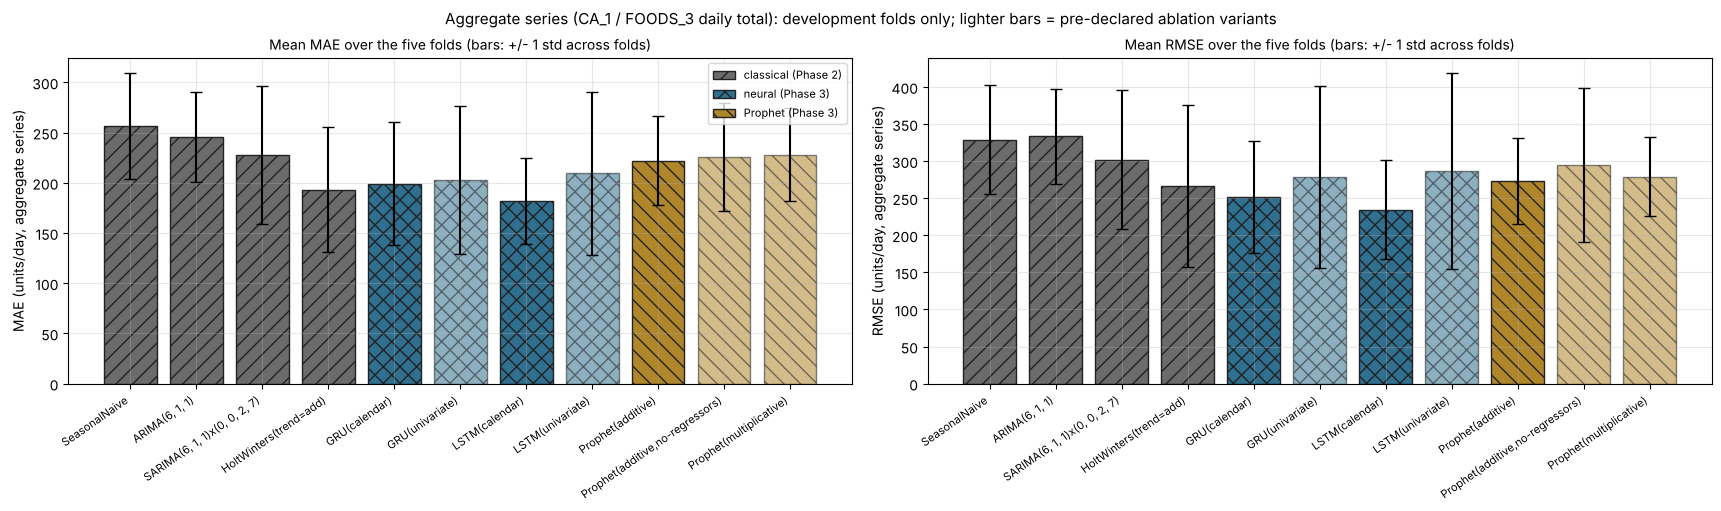

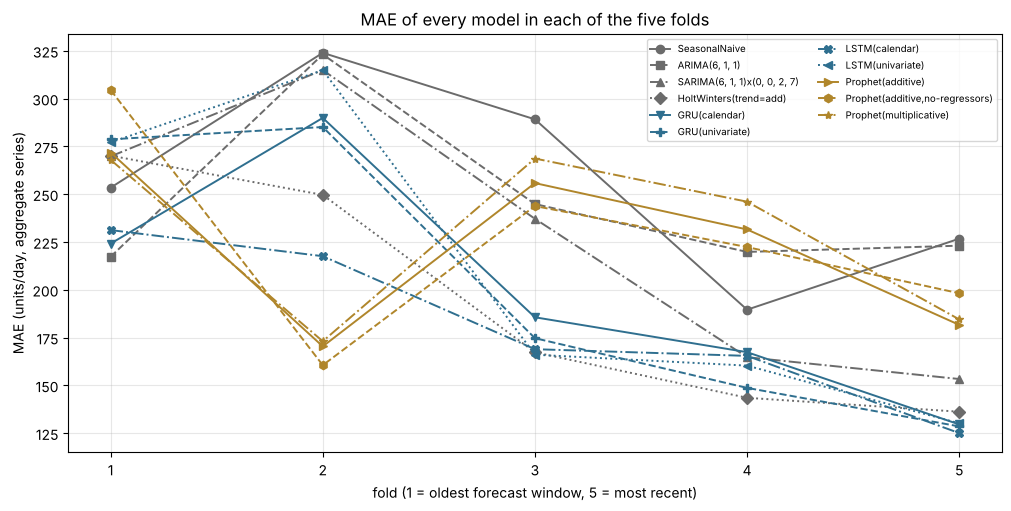

In [6]:
fig = mc.plot_aggregate_comparison(agg_summary.set_index("model").reindex(agg_models).reset_index())
save_figure(fig, p3["comparison_aggregate_plot_filename"])
plt.show()
fig = mc.plot_fold_variation(agg_folds, "MAE")
save_figure(fig, p3["comparison_aggregate_folds_plot_filename"])
plt.show()

### 5.3 Paired comparisons

In how many of the five folds does each model have a lower MAE than a reference? This is a count of 5 windows, **not** a test.

In [7]:
reference = "SeasonalNaive"
wins = mc.fold_wins(agg_folds, reference, "MAE")
display(wins.set_index("model").round(1))

best_phase2 = agg_summary[agg_summary["family"] == "classical (Phase 2)"].sort_values("MAE_mean").iloc[0]["model"] if (agg_summary["family"] == "classical (Phase 2)").any() else None
if best_phase2 and best_phase2 != reference:
    print(f"\nAgainst the Phase 2 model with the lowest mean MAE ({best_phase2}):")
    display(mc.fold_wins(agg_folds, best_phase2, "MAE").set_index("model").round(1))

print("\nAblation pairs (does extra information help? same model, with and without it; mean MAE over folds):")
pairs = []
for a, b, label in [("LSTM(calendar)", "LSTM(univariate)", "LSTM: calendar vs univariate"), ("GRU(calendar)", "GRU(univariate)", "GRU: calendar vs univariate"),
                    ("Prophet(additive)", "Prophet(additive,no-regressors)", "Prophet: with vs without regressors"), ("Prophet(additive)", "Prophet(multiplicative)", "Prophet: additive vs multiplicative")]:
    if a in agg_models and b in agg_models:
        ma, mb = agg_summary.set_index("model").loc[a, "MAE_mean"], agg_summary.set_index("model").loc[b, "MAE_mean"]
        fa = agg_folds[agg_folds["model"] == a].set_index("fold")["MAE"]
        fb = agg_folds[agg_folds["model"] == b].set_index("fold")["MAE"]
        pairs.append({"comparison": label, "first": a, "second": b, "MAE first": ma, "MAE second": mb, "first lower in folds": int((fa < fb).sum())})
if pairs:
    display(pd.DataFrame(pairs).set_index("comparison").round(1))
else:
    print("  (neither pair of variants is available)")

,reference,folds_compared,folds_lower,mean_difference
model,,,,
"ARIMA(6, 1, 1)",SeasonalNaive,5,4,-10.9
GRU(calendar),SeasonalNaive,5,5,-57.2
GRU(univariate),SeasonalNaive,5,4,-53.4
HoltWinters(trend=add),SeasonalNaive,5,4,-63.2
LSTM(calendar),SeasonalNaive,5,5,-74.9
LSTM(univariate),SeasonalNaive,5,4,-46.9
Prophet(additive),SeasonalNaive,5,3,-34.3
"Prophet(additive,no-regressors)",SeasonalNaive,5,3,-30.7
Prophet(multiplicative),SeasonalNaive,5,3,-28.5



Against the Phase 2 model with the lowest mean MAE (HoltWinters(trend=add)):


,reference,folds_compared,folds_lower,mean_difference
model,,,,
"ARIMA(6, 1, 1)",HoltWinters(trend=add),5,1,52.3
GRU(calendar),HoltWinters(trend=add),5,2,6.0
GRU(univariate),HoltWinters(trend=add),5,1,9.8
LSTM(calendar),HoltWinters(trend=add),5,3,-11.7
LSTM(univariate),HoltWinters(trend=add),5,2,16.3
Prophet(additive),HoltWinters(trend=add),5,1,28.9
"Prophet(additive,no-regressors)",HoltWinters(trend=add),5,1,32.5
Prophet(multiplicative),HoltWinters(trend=add),5,2,34.7
"SARIMA(6, 1, 1)x(0, 0, 2, 7)",HoltWinters(trend=add),5,1,34.6



Ablation pairs (does extra information help? same model, with and without it; mean MAE over folds):


,first,second,MAE first,MAE second,first lower in folds
comparison,,,,,
LSTM: calendar vs univariate,LSTM(calendar),LSTM(univariate),181.6,209.7,3
GRU: calendar vs univariate,GRU(calendar),GRU(univariate),199.3,203.1,1
Prophet: with vs without regressors,Prophet(additive),"Prophet(additive,no-regressors)",222.2,225.9,2
Prophet: additive vs multiplicative,Prophet(additive),Prophet(multiplicative),222.2,228.0,4


### 5.4 Reading the aggregate comparison (computed from the tables above)

In [8]:
lines = []
lowest = mc.lowest_by_metric(agg_summary)
for row in lowest.itertuples():
    lines.append(f"Lowest mean {row.metric} on the aggregate series: {row.lowest_model} ({row.value:.4g}).")
distinct = lowest["lowest_model"].nunique()
lines.append("All four measures pick the same model." if distinct == 1 else f"The four measures pick {distinct} different models, so the choice of measure changes the answer.")

summary_idx = agg_summary.set_index("model")
primary = [m for m in mc.PRIMARY_MODELS if m in summary_idx.index and not m.startswith("XGBoost")]
phase2_mae = summary_idx[summary_idx["family"] == "classical (Phase 2)"]["MAE_mean"]
if len(phase2_mae):
    best_model = phase2_mae.idxmin()
    for m in primary:
        diff = summary_idx.loc[m, "MAE_mean"] - phase2_mae.min()
        sd = summary_idx.loc[m, "MAE_std"]
        lower_folds = int((agg_folds[agg_folds["model"] == m].set_index("fold")["MAE"] < agg_folds[agg_folds["model"] == best_model].set_index("fold")["MAE"]).sum())
        lines.append(f"{m}: mean MAE {summary_idx.loc[m, 'MAE_mean']:.1f} vs {phase2_mae.min():.1f} for the best Phase 2 model ({best_model}) - difference {diff:+.1f} units/day; "
                     f"the fold-to-fold std of {m} is {sd:.1f}; lower than {best_model} in {lower_folds} of {N_FOLDS} folds.")
spread = summary_idx["MAE_std"].median()
lines.append(f"The median across-fold std of MAE is {spread:.1f} units/day; differences between models smaller than that should not be read as real.")
for line in lines:
    print("-", line)

- Lowest mean MAE on the aggregate series: LSTM(calendar) (181.6).
- Lowest mean RMSE on the aggregate series: LSTM(calendar) (234.7).
- Lowest mean WAPE on the aggregate series: LSTM(calendar) (0.09366).
- Lowest mean MASE on the aggregate series: LSTM(calendar) (0.6896).
- All four measures pick the same model.
- LSTM(calendar): mean MAE 181.6 vs 193.3 for the best Phase 2 model (HoltWinters(trend=add)) - difference -11.7 units/day; the fold-to-fold std of LSTM(calendar) is 42.9; lower than HoltWinters(trend=add) in 3 of 5 folds.
- GRU(calendar): mean MAE 199.3 vs 193.3 for the best Phase 2 model (HoltWinters(trend=add)) - difference +6.0 units/day; the fold-to-fold std of GRU(calendar) is 61.0; lower than HoltWinters(trend=add) in 2 of 5 folds.
- Prophet(additive): mean MAE 222.2 vs 193.3 for the best Phase 2 model (HoltWinters(trend=add)) - difference +28.9 units/day; the fold-to-fold std of Prophet(additive) is 44.7; lower than HoltWinters(trend=add) in 1 of 5 folds.
- The median 

## 6. Results: item level, the 20 selected items

*Scale: units of one product per day. Everything in this section is item-level; its numbers are never compared with Section 5.*

The item-level files are the Phase 2 baselines (Seasonal Naive, Croston, TSB) and the Phase 3 XGBoost variants. Notebook 05 re-ran the baselines; if its file is present, the notebook checks that it carries **identical** forecasts and counts it once.

In [9]:
item_models = []
if not item_tables:
    print("No item-level artifacts available; see the audit table above.")
else:
    item_table, item_notes = mc.combine_tables(item_tables, "item")
    for note in item_notes:
        print("note:", note)
    item_models = list(dict.fromkeys(item_table["model"]))
    print(f"{len(item_models)} item-level models on one identical grid ({item_table['item_id'].nunique()} items x {item_table['fold'].nunique()} folds x {HORIZON} days):")
    for model in item_models:
        print(f"  {mc.model_family(model, 'item'):22s} {model}{'   [primary]' if model in mc.PRIMARY_MODELS else ''}")
    item_folds = mc.item_fold_metrics(item_table, item_series, HORIZON, N_FOLDS)
    from src.evaluation.intermittent_experiment import item_summary

    item_items = item_summary(item_folds)
    item_classes = mc.item_model_class_summary(item_folds)
    overall = (
        item_items.groupby("model", sort=False)[["MAE_mean", "RMSE_mean", "WAPE_mean", "MASE_mean", "bias_mean"]].mean().reindex(item_models)
    )
    overall.insert(0, "n_items", item_items.groupby("model", sort=False)["item_id"].nunique().reindex(item_models))
    save_table(item_folds, "comparison_item_fold_filename")
    save_table(item_classes, "comparison_item_class_filename")
    save_table(overall.reset_index(), "comparison_item_summary_filename")
    print(f"\nFailed item-model folds in the saved tables: {int((~item_folds['success']).sum())} of {len(item_folds)}")

note: Croston(alpha=0.1): identical in item_level_backtest_long.csv and intermittent_item_level_backtest_long.csv; counted once (kept item_level_backtest_long.csv).
note: SeasonalNaive: identical in item_level_backtest_long.csv and intermittent_item_level_backtest_long.csv; counted once (kept item_level_backtest_long.csv).
note: TSB(alpha=0.1,beta=0.1): identical in item_level_backtest_long.csv and intermittent_item_level_backtest_long.csv; counted once (kept item_level_backtest_long.csv).
7 item-level models on one identical grid (20 items x 5 folds x 28 days):
  baseline (Phase 2)     Croston(alpha=0.1)
  baseline (Phase 2)     SeasonalNaive
  baseline (Phase 2)     TSB(alpha=0.1,beta=0.1)
  XGBoost (Phase 3)      XGBoost(per-item)
  XGBoost (Phase 3)      XGBoost(pooled)   [primary]
  XGBoost (Phase 3)      XGBoost(pooled,no-events)
  XGBoost (Phase 3)      XGBoost(pooled,poisson)



Failed item-model folds in the saved tables: 0 of 700


### 6.1 By demand class (macro average: every item counts equally)

Five items per class. The "overall" table at the end averages the 20 items equally; they are a *stratified* sample (5 per class), not a random sample of the catalogue, so it is a convenience summary and not an estimate for the whole department.

In [10]:
if item_tables:
    order = {c: i for i, c in enumerate(["Smooth", "Intermittent", "Erratic", "Lumpy"])}
    cols = ["demand_class", "model", "n_items", "MAE_macro_mean", "RMSE_macro_mean", "MAPE_macro_mean", "WAPE_macro_mean", "MASE_macro_mean", "bias_macro_mean"]
    table = item_classes[cols].rename(columns={"MAE_macro_mean": "MAE", "RMSE_macro_mean": "RMSE", "MAPE_macro_mean": "MAPE_%", "WAPE_macro_mean": "WAPE", "MASE_macro_mean": "MASE", "bias_macro_mean": "bias"})
    table["_r"] = table["demand_class"].map(order)
    display(table.sort_values(["_r", "model"], kind="stable").drop(columns="_r").round(3).set_index(["demand_class", "model"]))
    print("Overall macro mean over the 20 items (stratified sample):")
    display(overall.round(3))

n_items    MAE   RMSE  MAPE_%   WAPE   MASE   bias
demand_class model                                                                        
Smooth       Croston(alpha=0.1)               5  2.504  3.217  64.836  0.791  0.833 -0.098
             SeasonalNaive                    5  2.940  3.872  87.268  0.826  0.975  0.066
             TSB(alpha=0.1,beta=0.1)          5  2.298  3.035  67.613  0.658  0.771 -0.112
             XGBoost(per-item)                5  2.281  2.932  71.265  0.672  0.766  0.198
             XGBoost(pooled)                  5  2.144  2.812  66.489  0.627  0.725  0.038
             XGBoost(pooled,no-events)        5  2.181  2.845  66.569  0.634  0.734  0.054
             XGBoost(pooled,poisson)          5  2.165  2.828  67.142  0.628  0.729  0.085
Intermittent Croston(alpha=0.1)               5  1.032  1.318  58.047  1.603  3.420 -0.015
             SeasonalNaive                    5  1.103  1.549  77.801  1.662  3.709 -0.089
             TSB(alpha=0.1,beta=0.1)          5  0.946  1.223  51.700  1.673  3.330 -0.049
             XGBoost(per-item)                5  1.111  1.409  58.993  2.943  3.810  0.207
             XGBoost(pooled)                  5  0.977  1.276  67.695  1.936  3.266 -0.053
             XGBoost(pooled,no-events)        5  0.999  1.289  66.256  1.955  3.319  0.023
             XGBoost(pooled,poisson)          5  0.994  1.260  60.369  2.031  3.287  0.109
Erratic      Croston(alpha=0.1)               5  4.390  5.106  71.400  1.579  0.787  1.113
             SeasonalNaive                    5  4.039  5.117  78.123  1.202  0.742  0.736
             TSB(alpha=0.1,beta=0.1)          5  3.388  4.263  67.833  1.065  0.621  0.408
             XGBoost(per-item)                5  3.373  4.157  63.085  1.110  0.617  1.065
             XGBoost(pooled)                  5  3.520  4.221  64.104  1.168  0.627  1.297
             XGBoost(pooled,no-events)        5  3.413  4.155  65.821  1.106  0.616  1.158
             XGBoost(pooled,poisson)          5  3.446  4.164  63.320  1.178  0.618  1.289
Lumpy        Croston(alpha=0.1)               5  1.594  1.862  65.245  1.393  1.171  0.295
             SeasonalNaive                    5  1.289  1.795  90.879  1.326  1.002  0.014
             TSB(alpha=0.1,beta=0.1)          5  1.185  1.480  69.958  1.217  0.918  0.021
             XGBoost(per-item)                5  1.468  1.847  76.929  1.484  1.105  0.582
             XGBoost(pooled)                  5  1.277  1.559  68.887  1.359  0.967  0.264
             XGBoost(pooled,no-events)        5  1.269  1.553  68.850  1.352  0.963  0.250
             XGBoost(pooled,poisson)          5  1.299  1.593  67.309  1.369  0.974  0.328

Overall macro mean over the 20 items (stratified sample):


,n_items,MAE_mean,RMSE_mean,WAPE_mean,MASE_mean,bias_mean
model,,,,,,
Croston(alpha=0.1),20,2.380,2.876,1.341,1.553,0.324
SeasonalNaive,20,2.343,3.083,1.254,1.607,0.182
"TSB(alpha=0.1,beta=0.1)",20,1.954,2.500,1.153,1.410,0.067
XGBoost(per-item),20,2.058,2.586,1.552,1.574,0.513
XGBoost(pooled),20,1.980,2.467,1.273,1.396,0.387
"XGBoost(pooled,no-events)",20,1.965,2.461,1.262,1.408,0.371
"XGBoost(pooled,poisson)",20,1.976,2.461,1.301,1.402,0.453


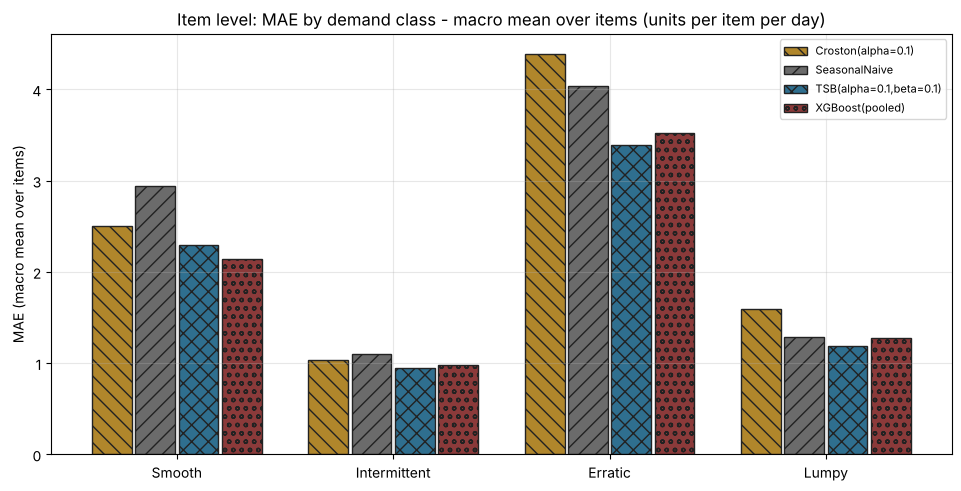

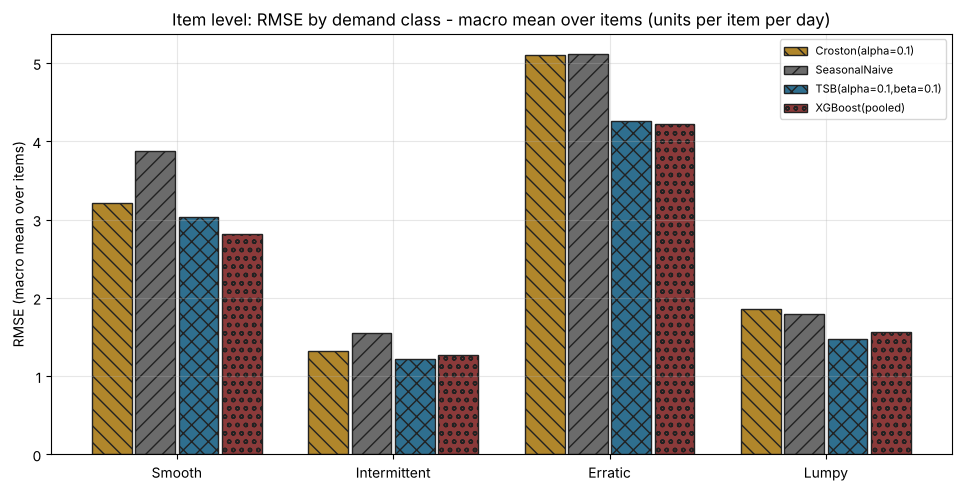

Plotted: the baselines and the primary XGBoost variant. The other XGBoost variants (per-item, no-events, Poisson) are in the tables.


In [11]:
if item_tables:
    plot_models = [m for m in ("SeasonalNaive", "Croston(alpha=0.1)", "TSB(alpha=0.1,beta=0.1)", "XGBoost(pooled)") if m in item_models]
    primary_classes = item_classes[item_classes["model"].isin(plot_models)]
    fig = plot_class_metric(primary_classes, "MAE", title="Item level: MAE by demand class - macro mean over items (units per item per day)")
    save_figure(fig, p3["comparison_item_plot_filename"])
    plt.show()
    fig = plot_class_metric(primary_classes, "RMSE", title="Item level: RMSE by demand class - macro mean over items (units per item per day)")
    save_figure(fig, p3["comparison_item_rmse_plot_filename"])
    plt.show()
    print("Plotted: the baselines and the primary XGBoost variant. The other XGBoost variants (per-item, no-events, Poisson) are in the tables.")

### 6.2 Variation between folds, by class

In [12]:
if item_tables:
    ok = item_folds[item_folds["success"].astype(bool)]
    by_fold = ok.groupby(["demand_class", "model", "fold"])["MAE"].mean().unstack("fold")
    by_fold.columns = [f"fold {c}" for c in by_fold.columns]
    by_fold["mean"] = by_fold.mean(axis=1)
    by_fold["std (folds)"] = by_fold[[c for c in by_fold.columns if c.startswith("fold")]].std(axis=1, ddof=1)
    by_fold = by_fold.reset_index()
    by_fold["_r"] = by_fold["demand_class"].map(order)
    display(by_fold.sort_values(["_r", "model"], kind="stable").drop(columns="_r").set_index(["demand_class", "model"]).round(3))
    print("Class-level MAE of each model in each fold (units per item per day, macro mean over the class's items).")

fold 1  fold 2  fold 3  fold 4  fold 5   mean  std (folds)
demand_class model                                                                                
Smooth       Croston(alpha=0.1)          2.866   2.545   2.312   2.338   2.458  2.504        0.223
             SeasonalNaive               3.029   3.279   2.700   2.893   2.800  2.940        0.225
             TSB(alpha=0.1,beta=0.1)     2.157   2.337   2.203   2.329   2.462  2.298        0.121
             XGBoost(per-item)           2.382   2.448   2.189   2.136   2.249  2.281        0.131
             XGBoost(pooled)             1.978   2.301   2.041   2.095   2.306  2.144        0.151
             XGBoost(pooled,no-events)   2.101   2.321   2.031   2.124   2.329  2.181        0.136
             XGBoost(pooled,poisson)     1.973   2.321   2.064   2.098   2.369  2.165        0.171
Intermittent Croston(alpha=0.1)          0.921   0.890   1.060   1.136   1.153  1.032        0.121
             SeasonalNaive               1.079   1.114   0.929   1.021   1.371  1.103        0.166
             TSB(alpha=0.1,beta=0.1)     0.932   0.928   0.822   0.889   1.156  0.946        0.126
             XGBoost(per-item)           1.216   1.379   0.807   0.869   1.286  1.111        0.257
             XGBoost(pooled)             0.970   1.057   0.806   0.898   1.154  0.977        0.135
             XGBoost(pooled,no-events)   1.019   1.058   0.800   0.969   1.147  0.999        0.129
             XGBoost(pooled,poisson)     0.989   1.068   0.790   0.957   1.169  0.994        0.141
Erratic      Croston(alpha=0.1)          7.231   3.810   2.794   2.932   5.182  4.390        1.851
             SeasonalNaive               3.550   3.957   3.000   3.643   6.043  4.039        1.172
             TSB(alpha=0.1,beta=0.1)     2.926   3.185   2.689   2.953   5.184  3.388        1.019
             XGBoost(per-item)           3.404   2.658   2.851   2.949   5.003  3.373        0.951
             XGBoost(pooled)             3.169   2.798   2.589   3.648   5.397  3.520        1.124
             XGBoost(pooled,no-events)   2.839   2.734   2.571   3.581   5.340  3.413        1.145
             XGBoost(pooled,poisson)     2.919   2.625   2.604   3.412   5.671  3.446        1.286
Lumpy        Croston(alpha=0.1)          1.591   1.523   1.617   1.539   1.700  1.594        0.071
             SeasonalNaive               0.643   1.307   1.579   1.714   1.200  1.289        0.415
             TSB(alpha=0.1,beta=0.1)     0.596   1.208   1.307   1.519   1.297  1.185        0.349
             XGBoost(per-item)           0.719   1.747   1.559   1.464   1.850  1.468        0.445
             XGBoost(pooled)             0.580   1.255   1.432   1.414   1.703  1.277        0.421
             XGBoost(pooled,no-events)   0.590   1.240   1.422   1.431   1.664  1.269        0.408
             XGBoost(pooled,poisson)     0.682   1.305   1.498   1.398   1.614  1.299        0.364

Class-level MAE of each model in each fold (units per item per day, macro mean over the class's items).


### 6.3 Reading the item-level comparison (computed from the tables above)

In [13]:
item_lines = []
if item_tables:
    for label in ["Smooth", "Intermittent", "Erratic", "Lumpy"]:
        part = item_classes[item_classes["demand_class"] == label]
        picks = {}
        for metric in ("MAE", "RMSE", "WAPE", "MASE"):
            valid = part.dropna(subset=[f"{metric}_macro_mean"])
            picks[metric] = valid.loc[valid[f"{metric}_macro_mean"].idxmin(), "model"] if len(valid) else "n/a"
        same = len(set(picks.values())) == 1
        item_lines.append(f"{label}: lowest macro-mean " + ", ".join(f"{k} {v}" for k, v in picks.items()) + (" (all four agree)." if same else " (the measures disagree)."))
    ref = "SeasonalNaive"
    if "XGBoost(pooled)" in item_models and ref in item_models:
        for label in ["Smooth", "Intermittent", "Erratic", "Lumpy"]:
            cls_folds = item_folds[(item_folds["demand_class"] == label) & item_folds["success"].astype(bool)]
            wide = cls_folds.groupby(["model", "fold"])["MAE"].mean().unstack("model")
            lower = int((wide["XGBoost(pooled)"] < wide[ref]).sum())
            item_lines.append(f"{label}: XGBoost(pooled) has a lower class-mean MAE than {ref} in {lower} of {len(wide)} folds.")
    spread = item_folds[item_folds["success"].astype(bool)].groupby(["demand_class", "model", "fold"])["MAE"].mean().groupby(["demand_class", "model"]).std().median()
    item_lines.append(f"The median across-fold std of a class-level MAE is {spread:.2f} units per item per day; model differences of that size or smaller are within the fold-to-fold noise.")
for line in item_lines:
    print("-", line)

- Smooth: lowest macro-mean MAE XGBoost(pooled), RMSE XGBoost(pooled), WAPE XGBoost(pooled), MASE XGBoost(pooled) (all four agree).
- Intermittent: lowest macro-mean MAE TSB(alpha=0.1,beta=0.1), RMSE TSB(alpha=0.1,beta=0.1), WAPE Croston(alpha=0.1), MASE XGBoost(pooled) (the measures disagree).
- Erratic: lowest macro-mean MAE XGBoost(per-item), RMSE XGBoost(pooled,no-events), WAPE TSB(alpha=0.1,beta=0.1), MASE XGBoost(pooled,no-events) (the measures disagree).
- Lumpy: lowest macro-mean MAE TSB(alpha=0.1,beta=0.1), RMSE TSB(alpha=0.1,beta=0.1), WAPE TSB(alpha=0.1,beta=0.1), MASE TSB(alpha=0.1,beta=0.1) (all four agree).
- Smooth: XGBoost(pooled) has a lower class-mean MAE than SeasonalNaive in 5 of 5 folds.
- Intermittent: XGBoost(pooled) has a lower class-mean MAE than SeasonalNaive in 5 of 5 folds.
- Erratic: XGBoost(pooled) has a lower class-mean MAE than SeasonalNaive in 4 of 5 folds.
- Lumpy: XGBoost(pooled) has a lower class-mean MAE than SeasonalNaive in 4 of 5 folds.
- The med

## 7. What the two comparisons do and do not support

* **Aggregate and item level are separate.** The aggregate series is the sum of 823 items; its errors are in thousands of units per day while an item's are in units. Nothing in this notebook ranks one against the other, and the same model name appearing in both (for example Seasonal Naive) does not make the numbers comparable.
* **Folds, not independent experiments.** Five consecutive 28-day windows overlap in their training data and share the same season of the year (Dec 2015 – Apr 2016). The across-fold standard deviation is a description of that variation, not a basis for a significance test.
* **Different information sets.** `LSTM(calendar)`, `Prophet(additive)` and the XGBoost variants with events use calendar information that is known in advance; the Phase 2 models and the univariate/no-regressor variants use only the series' own history. The ablation pairs in Section 5.3 isolate that.
* **Different measures can disagree.** MAE, RMSE, WAPE and MASE weight errors differently; on intermittent items MAE rewards low forecasts (notebook 05, Section 9), so the table of lowest models per measure matters more than any single column.

## 8. Limitations

* **One store, one department, five folds** (Dec 2015 – Apr 2016). Nothing here establishes how any model performs elsewhere or in another season.
* **Twenty items.** The item-level comparison uses 5 items per class chosen in Phase 1; classes are Phase 1 full-history labels here (notebook 05 Section 11 quantifies how fold-local labels differ).
* **Fixed settings, no tuning.** Every model uses settings fixed before any result existed. A tuned model could rank differently; tuning on these folds would require a separate, nested protocol.
* **No significance testing.** No test is justified by five overlapping folds; differences are descriptive.
* **Aggregate vs item-level.** Different scales; no cross-ranking by design.
* **Saved forecasts only.** If an artifact is missing, that model is absent, and the comparison says so; the notebook cannot tell whether the model would have been better or worse.
* **The final holdout (2016-04-25 → 2016-05-22) is untouched.** Nothing in this notebook is evidence about final performance; the holdout is evaluated once, later, under the freeze procedure in `MERGE_AND_RUN_WINDOWS.md`.

## 9. Conclusion

In [14]:
available_agg = [m for m in agg_models]
metadata = build_run_metadata(
    "comparison", config=config, config_keys=["backtest", "comparison"],
    extra={
        "aggregate_models": available_agg,
        "item_models": item_models,
        "artifacts_ok": audit[audit["status"] == "ok"]["artifact"].tolist(),
        "artifacts_unavailable": audit[audit["status"] != "ok"]["artifact"].tolist(),
        "artifact_sha256_prefix": {name: file_sha256(PROJECT_ROOT / p3["forecasts_dir"] / name)[:12] for name in audit[audit["status"] == "ok"]["artifact"]},
        "folds": N_FOLDS, "horizon": HORIZON, "significance_tests": "none",
    },
)
write_json(metrics_dir / p3["comparison_metadata_filename"], metadata)

print(f"Aggregate series: {len(available_agg)} models compared; item level: {len(item_models)} models compared (20 items).")
print(f"Unavailable artifacts: {len(problems)}" + ("" if problems.empty else " -> " + ", ".join(problems['artifact'])))
print("\nAggregate series (computed above):")
for line in lines:
    print(" -", line)
print("\nItem level (computed above; separate scale):")
for line in item_lines:
    print(" -", line)
print("\nStatus: development folds only; descriptive, no significance test; no universal winner claimed; aggregate and item-level never ranked together; final holdout (2016-04-25 to 2016-05-22) not used.")
print("Saved: 7 tables and metadata in artifacts/metrics/, 4 figures (plus 1 RMSE-by-class figure) in reports/phase3/.")

Aggregate series: 11 models compared; item level: 7 models compared (20 items).
Unavailable artifacts: 0

Aggregate series (computed above):
 - Lowest mean MAE on the aggregate series: LSTM(calendar) (181.6).
 - Lowest mean RMSE on the aggregate series: LSTM(calendar) (234.7).
 - Lowest mean WAPE on the aggregate series: LSTM(calendar) (0.09366).
 - Lowest mean MASE on the aggregate series: LSTM(calendar) (0.6896).
 - All four measures pick the same model.
 - LSTM(calendar): mean MAE 181.6 vs 193.3 for the best Phase 2 model (HoltWinters(trend=add)) - difference -11.7 units/day; the fold-to-fold std of LSTM(calendar) is 42.9; lower than HoltWinters(trend=add) in 3 of 5 folds.
 - GRU(calendar): mean MAE 199.3 vs 193.3 for the best Phase 2 model (HoltWinters(trend=add)) - difference +6.0 units/day; the fold-to-fold std of GRU(calendar) is 61.0; lower than HoltWinters(trend=add) in 2 of 5 folds.
 - Prophet(additive): mean MAE 222.2 vs 193.3 for the best Phase 2 model (HoltWinters(trend=ad

### How to reproduce

```powershell
python -m pytest tests/evaluation/test_model_comparison.py
python -m jupyter nbconvert --to notebook --execute --inplace notebooks/09_model_comparison.ipynb
```

Run the model notebooks first (04, 05, 06, 07, 08) so that their forecast files exist. The logic is in `src/evaluation/model_comparison.py`; filenames come from `config.yaml` (`phase2`, `phase3`).